# Step 1: Temporal History Analysis

**BT4222 Final Project, Group 13, JDSearch**

The task is to rerank the candidate products returned for a user's current
search query, using that user's preceding interactions as context. Each session
comes with two lists: a **candidate list** with graded labels (0 = no interaction,
1 = click, 2 = cart, 3 = purchase), and a **history list** of preceding events
(`CLICK`, `CART`, `ORD`, `FLW`).

Before building features from history, this notebook measures **how far back each
action type is observable**. In JDSearch, historical orders and carts vastly
outnumber clicks: millions of orders/carts carry no recorded click anywhere in
the same user's history. Whether that reflects real user behaviour or a
per-action logging window changes how history features should be designed, so
this notebook reconstructs the timeline directly from the data.

## History semantics

* `history_{qry,wid,type}_list` each have **n** values (one per historical event).
* `history_time_list` has **n+1** values:
  `[0, gap(e0->e1), ..., gap(e_{n-1}->test_query)]`.
* Therefore `elapsed_seconds_before_query[i] = sum(time[i+1:])` (suffix sum) and
  `elapsed_days[i] = elapsed_seconds[i] / 86400`.

## What this notebook computes

**Part A**: interaction-type composition and click-share decay by elapsed-day
bin. Produces `temporal_type_by_daybin.csv` and `temporal_summary.txt`.

**Part B**: daily retention table (0..366 days, 366 = "≥366 days") per action
type. Produces `retention_daily.csv` and `retention_cutoffs.txt`.

Three diagrams are rendered inline: the composition stack, the click-share
decay, and the daily logging horizons.

The retention numbers from Part B pin the observable horizons precisely. Across
all 173,831 users, **no click is observed older than ~13 days**, carts stop
appearing after ~90 days, follows after ~89 days, and orders extend to nearly
a full year (last occupied order day-bin = 364, with zero orders at ≥365 days).
These cut-offs are what motivate the short-intent (≤7d clicks, ≤90d carts)
versus long-preference (any-order) split used in Step 3's feature engineering.

## How to read this notebook

Every code cell is taken from `src/step1_preprocess_temporal.py` (Part A) or `src/step1b_retention_cutoffs.py`
(Part B). Each cell is preceded by an explanation, and the table links every section to the file it writes.
Unlike Steps 2 to 7, this step reads the **full raw file** (173,831 users), so the outputs saved below come
from a run on the raw data.

| Section | What it does | Writes |
|---|---|---|
| A.1 to A.4 | Constants, accumulators, load the raw file, one pass over every user | - |
| A.5, A.6 | Composition table and headline numbers | `temporal_type_by_daybin.csv`, `temporal_summary.txt` |
| A.7, A.8 | Stacked and line charts (inline) | - |
| B.1, B.2 | Daily counts by action type and summary text | `retention_daily.csv`, `retention_cutoffs.txt` |
| B.3 | Observed logging horizons chart (inline) | - |


## 0. Environment setup

The first cell finds the project and puts `src/` on `sys.path`, so `config`, `data_utils`
and `eval_utils` can be imported exactly as the scripts do.

* **In Colab** it clones the repository (branch set in `BRANCH`). Set `MOUNT_DRIVE = True` if the
  raw files live on Google Drive: raw paths and the output folder then point to Drive, so the
  outputs of one step survive until the next notebook.
* **Locally** it looks for `Final Project/` next to the notebook.
* All paths come from environment variables read by `src/config.py`:
  `JD_USER_TXT`, `JD_PRODUCT_TXT` (raw files), `JD_RUN_DIR` (where outputs are written, default
  `artifacts/corrected`), `JD_SEED` (default 42).

In [ ]:
# Optional: install dependencies in a fresh environment (Colab already has most of them)
# !pip -q install numpy pandas pyarrow scipy scikit-learn lightgbm joblib matplotlib torch

import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/steffanylars/nus-web-mining-business-insights.git"
BRANCH = "steff-coldstart-diversity"   # change to the team's final branch before submission
MOUNT_DRIVE = False                    # Colab only: True keeps raw data and outputs on Google Drive
DRIVE_DIR = "/content/drive/MyDrive/JDsearch"

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if MOUNT_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
        os.environ.setdefault("JD_USER_TXT", f"{DRIVE_DIR}/user_behavior_data.txt")
        os.environ.setdefault("JD_PRODUCT_TXT", f"{DRIVE_DIR}/product_meta_data.txt")
        os.environ.setdefault("JD_RUN_DIR", f"{DRIVE_DIR}/runs/corrected")
    repo = Path("/content/nus-web-mining-business-insights")
    if not (repo / ".git").exists():
        subprocess.run(["git", "clone", "--branch", BRANCH, REPO_URL, str(repo)], check=True)
    PROJECT_ROOT = repo / "Final Project"
else:
    here = Path.cwd()
    options = [here, here.parent, here / "Final Project", here.parent / "Final Project"]
    PROJECT_ROOT = next((p for p in options if (p / "src" / "config.py").exists()), None)
    assert PROJECT_ROOT is not None, "open this notebook from Final Project/ or Final Project/notebooks/"

SRC = PROJECT_ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))
print("in Colab    :", IN_COLAB)
print("project root:", PROJECT_ROOT)
print("run dir     :", os.environ.get("JD_RUN_DIR", "<default: artifacts/corrected>"))

## 1. Imports and shared helpers

`config.prepare()` creates the artifact directory used to write CSVs.
`data_utils.elapsed_days()` converts the raw interval list into per-event ages,
and `data_utils.split_list()` performs the underscore-split used by the
history-list columns.

`ART` is an alias for `RES` so the code below is identical to
`step1_preprocess_temporal.py`.

`%matplotlib inline` makes every `plt.show()` render as a notebook output cell.
No figures are written to disk.


In [11]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from config import SRC_USER, RES as ART, prepare
from data_utils import elapsed_days, split_list

prepare()
print("raw user file:", SRC_USER)
print("artifacts   :", ART)
assert SRC_USER.exists(), "Set JD_USER_TXT or place the raw file at data/user_behavior_data.txt" 

raw user file: C:\Users\Acer\OneDrive - National University of Singapore\BT4222\JDsearch\user_behavior_data.txt
artifacts   : C:\Users\Acer\OneDrive - National University of Singapore\BT4222\project code\nus-web-mining-business-insights\Final Project\artifacts\corrected


# Part A: Interaction-type composition by elapsed-day bin

For every historical event we compute its age (in days) before the current
query, bucket it into one of nine bins ranging from `<1min` to `>365d`, and
accumulate counts per action type. Two views are rendered:

* a stacked composition bar chart of the CLICK/CART/ORD/FLW share per bin,
* a line chart of the same shares across bins.

Part A's working artifacts written to `ART` are `temporal_type_by_daybin.csv`
and `temporal_summary.txt`.


### A.1 Constants

Action types, day-bin edges, human-readable labels, and plot colors. `EDGES`
starts with a sentinel `0` so `np.digitize(days, EDGES[1:])` returns integer bins
matching `LABELS` exactly.


In [12]:
TYPES  = ["CLICK", "CART", "ORD", "FLW"]
EDGES  = [0, 1/1440, 1/24, 1, 7, 30, 90, 180, 365, np.inf]
LABELS = ["<1min", "1min-1h", "1h-1d", "1-7d", "7-30d",
          "30-90d", "90-180d", "180-365d", ">365d"]
colors = {"CLICK": "#2b7bba", "CART": "#2ca089", "ORD": "#d2691e", "FLW": "#999999"}

### A.2 Accumulators

`counts[type][bin]` is the per-bin count of each action type.
`recent_counts` / `old_counts` are the headline accumulators for ≤1 day and
>30 days.


In [13]:
counts           = np.zeros((len(TYPES), len(LABELS)), dtype=np.int64)
type_idx         = {t: i for i, t in enumerate(TYPES)}
total_events     = 0
old_counts       = np.zeros(len(TYPES), dtype=np.int64)
recent_counts    = np.zeros(len(TYPES), dtype=np.int64)

### A.3 Load the raw user file

`dtype=str` keeps the underscore-joined list columns as plain strings; they are
split in Python during the scan. This is the only memory-resident copy of the
raw table.


In [14]:
t0 = time.time()
print("Loading user_behavior_data.txt...", flush=True)
df = pd.read_csv(SRC_USER, sep="\t", dtype=str, low_memory=False)
n_users = len(df)
print(f"  users: {n_users:,}  ({time.time()-t0:.0f}s)", flush=True)

Loading user_behavior_data.txt...
  users: 173,831  (13s)


### A.4 Single pass over every user

For each user row:

1. Split `history_type_list` and `history_time_list` on `_`.
2. Reconstruct per-event ages via `elapsed_days(gaps, n)`.
3. Bucket each event's age into one of the nine bins and accumulate `counts`.
4. Accumulate the recent (≤1 day) and old (>30 day) headline counts.
5. Print progress every 20,000 users.


In [15]:
def split(v):
    if v is None or (isinstance(v, float)) or str(v) == "nan" or str(v).strip() == "":
        return []
    return str(v).split("_")

t1 = time.time()
for ridx, (types_s, times_s) in enumerate(zip(df["history_type_list"].values,
                                              df["history_time_list"].values)):
    types = split(types_s)
    times = split(times_s)
    n = len(types)
    if n == 0:
        continue
    gaps = np.asarray([float(x) for x in times])
    days_checked = elapsed_days(gaps, n)
    elapsed = days_checked * 86400.
    days = elapsed / 86400.0
    bins = np.digitize(days, EDGES[1:], right=False)
    bins = np.clip(bins, 0, len(LABELS) - 1)
    for ti, b in zip(types, bins):
        ci = type_idx.get(ti)
        if ci is None:
            continue
        counts[ci, b] += 1
        total_events += 1
    d = days
    for ti, dd in zip(types, d):
        ci = type_idx.get(ti)
        if ci is None:
            continue
        if dd <= 1.0:
            recent_counts[ci] += 1
        elif dd > 30.0:
            old_counts[ci] += 1
    if ridx % 20000 == 0 and ridx > 0:
        print(f"  processed {ridx:,}/{n_users:,} users  ({time.time()-t1:.0f}s)", flush=True)

print(f"Parsed all histories. total events={total_events:,}  ({time.time()-t0:.0f}s)", flush=True)

  processed 20,000/173,831 users  (11s)
  processed 40,000/173,831 users  (21s)
  processed 60,000/173,831 users  (34s)
  processed 80,000/173,831 users  (46s)
  processed 100,000/173,831 users  (59s)
  processed 120,000/173,831 users  (71s)
  processed 140,000/173,831 users  (82s)
  processed 160,000/173,831 users  (93s)
Parsed all histories. total events=26,667,260  (118s)


### A.5 Composition table

`tbl` contains absolute counts per bin plus per-bin shares of each action type.
Written to `temporal_type_by_daybin.csv` and printed for inspection.


In [16]:
col_tot = counts.sum(axis=0)
comp    = counts / np.maximum(col_tot, 1)
tbl     = pd.DataFrame(counts.T, index=LABELS, columns=TYPES)
tbl["total_events"] = col_tot
for t in TYPES:
    tbl[f"{t}_share"] = (counts[type_idx[t]] / np.maximum(col_tot, 1))
tbl.to_csv(ART / "temporal_type_by_daybin.csv")
print("\n=== Interaction-type composition by elapsed-days-before-query bin ===")
print(tbl[[*TYPES, "total_events", "CLICK_share", "CART_share", "ORD_share"]].to_string())


=== Interaction-type composition by elapsed-days-before-query bin ===
            CLICK     CART      ORD    FLW  total_events  CLICK_share  CART_share  ORD_share
<1min       64201    10118     1730      9         76058     0.844106    0.133030   0.022746
1min-1h    557917    84790     7936    117        650760     0.857331    0.130294   0.012195
1h-1d     1296171   192320    26775    490       1515756     0.855132    0.126881   0.017664
1-7d      6380498  1047929   166381   2035       7596843     0.839888    0.137943   0.021901
7-30d         107  3300950   553008   7419       3861484     0.000028    0.854840   0.143211
30-90d          0  6889193  1280095  14509       8183797     0.000000    0.841809   0.156418
90-180d         0     1203  1824126      0       1825329     0.000000    0.000659   0.999341
180-365d        0        0  2957232      0       2957232     0.000000    0.000000   1.000000
>365d           0        1        0      0             1     0.000000    1.000000   0.000000

### A.6 Headline numbers (`temporal_summary.txt`)

The recent (≤1 day) versus old (>30 days) comparison is deliberately asymmetric:
**85.54%** of events within the last day are clicks, while the >30 day bucket
contains **zero** clicks: 6.89M carts and 6.06M orders, but not a single
clicked item.

The same computation across all bins establishes the click horizon for the
supplied data: the share drops from ~84 to 86% in every bin up to 7 days to
**0.0028%** in the 7-30d bin (107 events) and **exactly 0%** in every bin
beyond. The last occupied click day-bin is 13.

Written to disk so the report can quote the exact numbers.

In [17]:
rec_tot = recent_counts.sum(); old_tot = old_counts.sum()
lines = []
lines.append("TEMPORAL HISTORY ANALYSIS - headline numbers")
lines.append("")
lines.append(f"Total historical events parsed: {total_events:,}")
lines.append("")
lines.append("Within <=1 day before the test query:")
for t in TYPES:
    c = recent_counts[type_idx[t]]
    lines.append(f"   {t:6s}: {c:>12,}  ({100*c/max(rec_tot,1):5.2f}% of recent events)")
lines.append(f"   recent click share = {100*recent_counts[type_idx['CLICK']]/max(rec_tot,1):.2f}%")
lines.append("")
lines.append("More than 30 days before the test query:")
for t in TYPES:
    c = old_counts[type_idx[t]]
    lines.append(f"   {t:6s}: {c:>12,}  ({100*c/max(old_tot,1):5.2f}% of old events)")
lines.append(f"   old click share = {100*old_counts[type_idx['CLICK']]/max(old_tot,1):.2f}%")
lines.append("")
lines.append("Click share by bin (near -> far in time):")
for lab in LABELS:
    lines.append(f"   {lab:10s}: CLICK {100*tbl.loc[lab,'CLICK_share']:5.2f}%  "
                 f"CART {100*tbl.loc[lab,'CART_share']:5.2f}%  "
                 f"ORD {100*tbl.loc[lab,'ORD_share']:5.2f}%  "
                 f"(n={int(tbl.loc[lab,'total_events']):,})")
txt = "\n".join(lines)
(ART / "temporal_summary.txt").write_text(txt)
print("\n" + txt)


TEMPORAL HISTORY ANALYSIS - headline numbers

Total historical events parsed: 26,667,260

Within <=1 day before the test query:
   CLICK :    1,918,323  (85.54% of recent events)
   CART  :      287,230  (12.81% of recent events)
   ORD   :       36,441  ( 1.62% of recent events)
   FLW   :          616  ( 0.03% of recent events)
   recent click share = 85.54%

More than 30 days before the test query:
   CLICK :            0  ( 0.00% of old events)
   CART  :    6,890,396  (53.14% of old events)
   ORD   :    6,061,453  (46.75% of old events)
   FLW   :       14,509  ( 0.11% of old events)
   old click share = 0.00%

Click share by bin (near -> far in time):
   <1min     : CLICK 84.41%  CART 13.30%  ORD  2.27%  (n=76,058)
   1min-1h   : CLICK 85.73%  CART 13.03%  ORD  1.22%  (n=650,760)
   1h-1d     : CLICK 85.51%  CART 12.69%  ORD  1.77%  (n=1,515,756)
   1-7d      : CLICK 83.99%  CART 13.79%  ORD  2.19%  (n=7,596,843)
   7-30d     : CLICK  0.00%  CART 85.48%  ORD 14.32%  (n=3,861,48

### A.7 Composition across elapsed-day bins (inline)

Stacked bar chart of the CLICK/CART/ORD/FLW share within each bin. The x-axis
orders bins from most recent (`<1min`) to oldest (`>365d`).


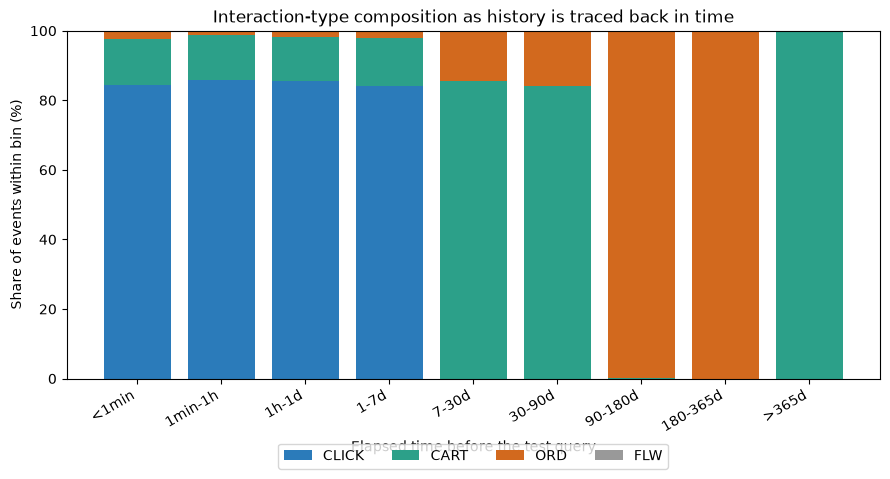

In [18]:
fig, ax = plt.subplots(figsize=(9, 5))
bottom = np.zeros(len(LABELS))
for t in TYPES:
    vals = tbl[f"{t}_share"].values * 100
    ax.bar(LABELS, vals, bottom=bottom, label=t, color=colors[t])
    bottom += vals
ax.set_ylabel("Share of events within bin (%)")
ax.set_xlabel("Elapsed time before the test query")
ax.set_title("Interaction-type composition as history is traced back in time")
ax.legend(ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.28))
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### A.8 Click-share decay (inline)

The same composition viewed as a line chart, emphasising how CLICK share
collapses with age while ORD persists.


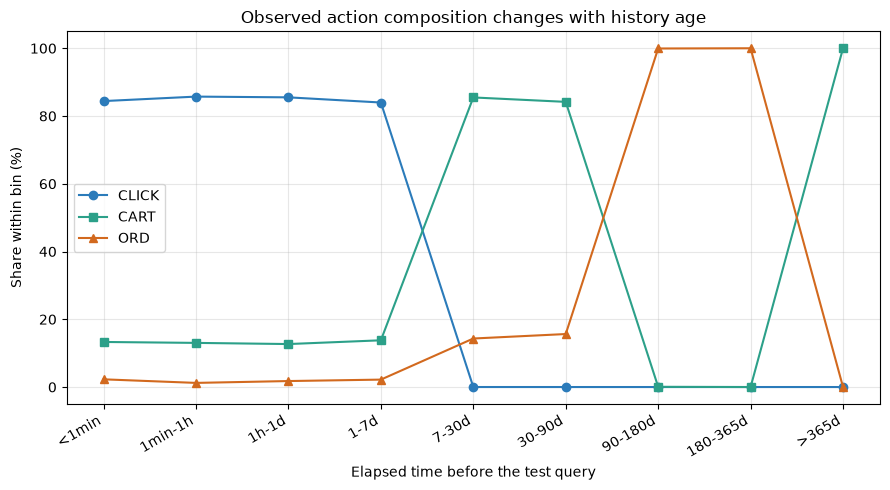

In [19]:
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(LABELS))
ax.plot(x, tbl["CLICK_share"].values * 100, "o-", color=colors["CLICK"], label="CLICK")
ax.plot(x, tbl["CART_share"].values  * 100, "s-", color=colors["CART"],  label="CART")
ax.plot(x, tbl["ORD_share"].values   * 100, "^-", color=colors["ORD"],   label="ORD")
ax.set_xticks(x); ax.set_xticklabels(LABELS, rotation=30, ha="right")
ax.set_ylabel("Share within bin (%)"); ax.set_xlabel("Elapsed time before the test query")
ax.set_title("Observed action composition changes with history age")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Part B: Daily retention table

Same reconstruction but with daily bins (0..366, where 366 means "≥366 days")
and per-action-type counts. This is a stricter view of the same timeline: instead
of nine coarse bins we keep every integer day, so drop-offs around 7 days
(clicks) and 90 days (carts), and the long tail of orders, are directly
visible.

Part B's working artifacts written to `ART` are `retention_daily.csv` and
`retention_cutoffs.txt`. The three views in this notebook (A.7, A.8, B.3) are
rendered inline only.

The read-out is conservative: sharp drops around 7/90 days are consistent with
different logging windows and are not claimed as JD's actual retention policy.


### B.1 Daily counts by action type

Stream the raw user file with `csv.DictReader` and accumulate a `(367, 4)` count
matrix: one row per integer day (0..365 plus 366 for "≥366"), one column per
action type. Each event is floored to the nearest day and capped at 366.


In [20]:
types_b  = ['CLICK', 'CART', 'ORD', 'FLW']
counts_b = np.zeros((367, 4), dtype=np.int64)
for_row  = 0

with SRC_USER.open(encoding='utf-8', newline='') as f:
    for row in csv.DictReader(f, delimiter='\t'):
        acts = np.array(split_list(row['history_type_list']))
        days = elapsed_days([float(x) for x in split_list(row['history_time_list'])], len(acts))
        bins = np.minimum(np.floor(days).astype(int), 366)
        for i, t in enumerate(types_b):
            counts_b[:, i] += np.bincount(bins[acts == t], minlength=367)
        for_row += 1

table_b = pd.DataFrame(counts_b, columns=types_b)
table_b.index.name = 'elapsed_day_floor_366_is_overflow'
table_b.to_csv(ART / 'retention_daily.csv')
print(f"scanned {for_row:,} users")

scanned 173,831 users


### B.2 Summary text (`retention_cutoffs.txt`)

For each action type we record the total event count and the largest non-empty
day bin. The result makes the sharp separations between action types concrete:

| action | total events | last occupied day bin |
|---|---:|---:|
| CLICK | 8,298,894 | 13 |
| FLW   | 24,579 | 89 |
| CART  | 11,526,504 | 366 |
| ORD   | 6,817,283 | 364 |

The cart figure of 366 is a single stray event; the meaningful cut-off is around
day 90, where the composition table shows the share fall from ~84% to 0.07%.
The order figure of 364 combined with **`Orders aged >=365 days: 0`** means the
observed order tail stops two days short of a full year: no order at or beyond
day 365 is present in this sample.

Click and follow both have short horizons (day 13 and day 89 respectively),
which is why neither is used in the long-preference profile of Step 3.

In [21]:
lines_b = ['Observed daily action-age counts, not verified JD retention policy.',
           f'Users: {for_row:,}. Bins [d,d+1); 366 is >=366 days.',
           'Sharp drops around 7/90 days are consistent with different logging windows.',
           'Rare events remain outside those approximate windows.']
for i, t in enumerate(types_b):
    nonzero = np.flatnonzero(counts_b[:, i])
    lines_b.append(f'{t}: total={counts_b[:,i].sum():,}, '
                   f'last occupied day bin={nonzero.max() if len(nonzero) else None}')
lines_b.append(f'Orders aged >=365 days: {int(counts_b[365:, 2].sum())}')
(ART / 'retention_cutoffs.txt').write_text('\n'.join(lines_b), encoding='utf-8')
print("\n".join(lines_b))

Observed daily action-age counts, not verified JD retention policy.
Users: 173,831. Bins [d,d+1); 366 is >=366 days.
Sharp drops around 7/90 days are consistent with different logging windows.
Rare events remain outside those approximate windows.
CLICK: total=8,298,894, last occupied day bin=13
CART: total=11,526,504, last occupied day bin=366
ORD: total=6,817,283, last occupied day bin=364
FLW: total=24,579, last occupied day bin=89
Orders aged >=365 days: 0


### B.3 Observed logging horizons (inline)

The same daily counts plotted with a symlog y-axis so both the sharp 7/90 day
drops and the small long tail are visible at once.


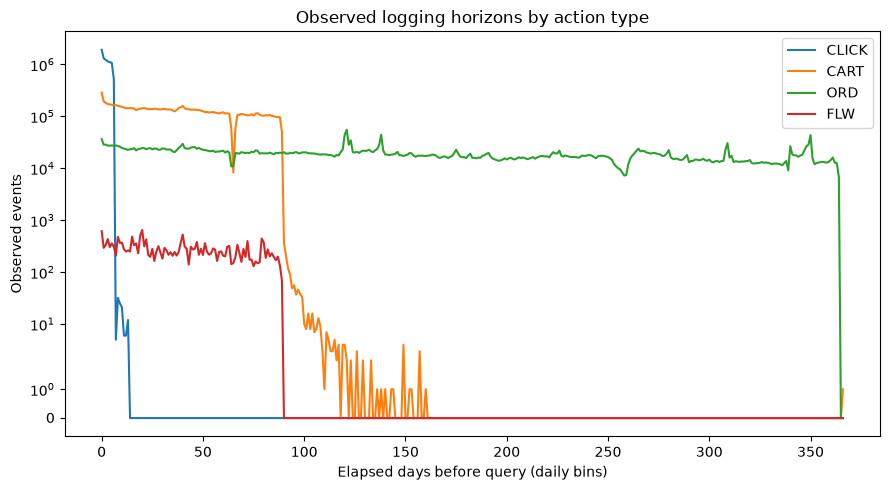

In [22]:
fig, ax = plt.subplots(figsize=(9, 5))
for t in types_b:
    ax.plot(table_b.index, table_b[t], label=t)
ax.set(yscale='symlog', xlabel='Elapsed days before query (daily bins)',
       ylabel='Observed events', title='Observed logging horizons by action type')
ax.legend(); fig.tight_layout()
plt.show()

# Summary

**Part A**: `temporal_type_by_daybin.csv` and `temporal_summary.txt` quantify
how the CLICK share collapses with age while ORD persists. The inline stacked
and line charts (`A.7`, `A.8`) show the same table.

**Part B**: `retention_daily.csv` and `retention_cutoffs.txt` show sharp drops
around 7 days (clicks) and 90 days (carts); orders extend much further. The
inline symlog chart (`B.3`) makes both the drop-offs and the tail visible.

These observed distributions motivate the short-intent (≤7d clicks, ≤90d carts)
versus long-preference (any-order) split used in Step 3's feature engineering.
They are measurements of the supplied data, not claims about JD's internal
logging policy: absent older clicks are unobserved, not evidence of no interest.
